# Problem 2 — Transformer from scratch

No `nn.MultiheadAttention` or `nn.Transformer` in the model code. Library attention is only used in the check below.

Training outputs are already in `results.csv`, `problem2/figures/` and `generated_samples.txt`.

In [1]:
import sys
from pathlib import Path
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))

## Attention check

In [2]:
from problem2.run_pipeline import test_attention
from problem2.attention import hand_check_attention_example
from problem2.encoder import EncoderBlock, encoder_block_param_count

test_attention()
ex = hand_check_attention_example()
print(ex['weights'])
print('row sums', ex['weights'].sum(-1))

block = EncoderBlock(128, 4, 512)
print('derived', encoder_block_param_count(128, 512), 'actual', sum(p.numel() for p in block.parameters()))

tensor([[1.0000, 0.0000, 0.0000],
        [0.3302, 0.6698, 0.0000],
        [0.2483, 0.2483, 0.5035]])
row sums tensor([1., 1., 1.])
derived 198272 actual 198272


## Saved language-model results

                         model  val_loss_nats  bits_per_char           notes
47        transformer_har_none            NaN            NaN             HAR
48  transformer_har_sinusoidal            NaN            NaN             HAR
49     transformer_har_learned            NaN            NaN             HAR
50        transformer_har_none            NaN            NaN             HAR
51  transformer_har_sinusoidal            NaN            NaN             HAR
52     transformer_har_learned            NaN            NaN             HAR
53        transformer_har_none            NaN            NaN             HAR
54  transformer_har_sinusoidal            NaN            NaN             HAR
55     transformer_har_learned            NaN            NaN             HAR
56              transformer_lm       1.522513       2.196522     shakespeare
57              transformer_lm       1.513002       2.182800         heads=1
58              transformer_lm       1.522513       2.196522         heads=4

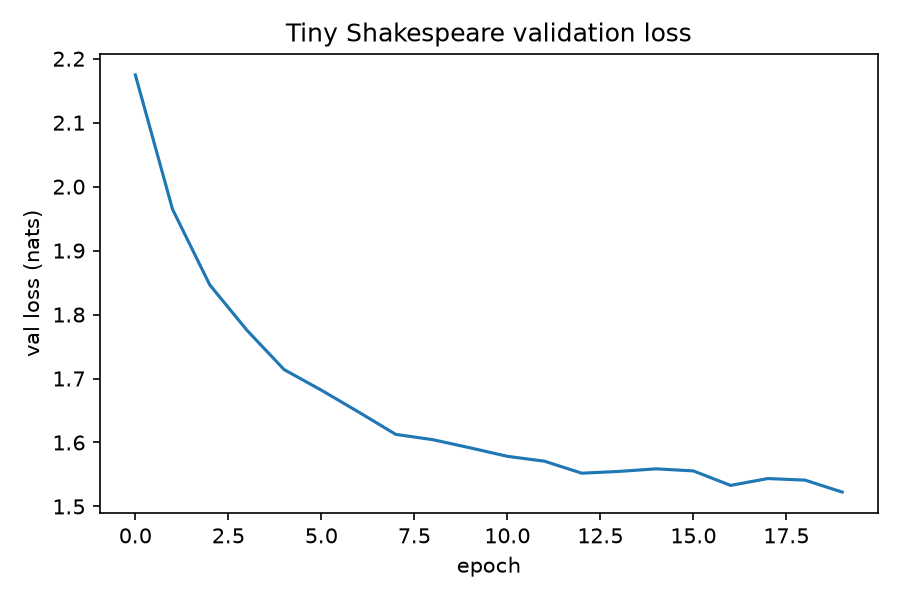

attention_heatmaps.png


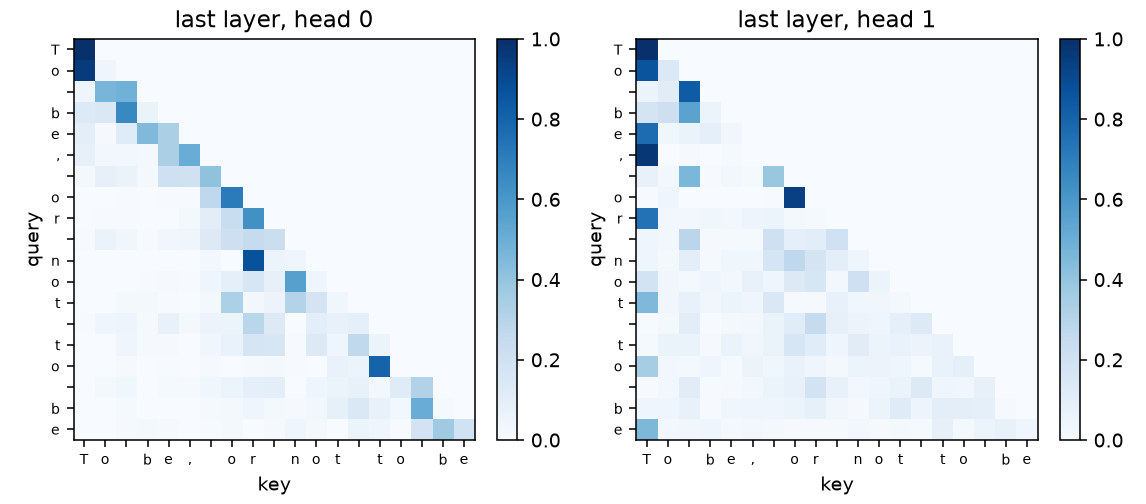

heads_ablation.png


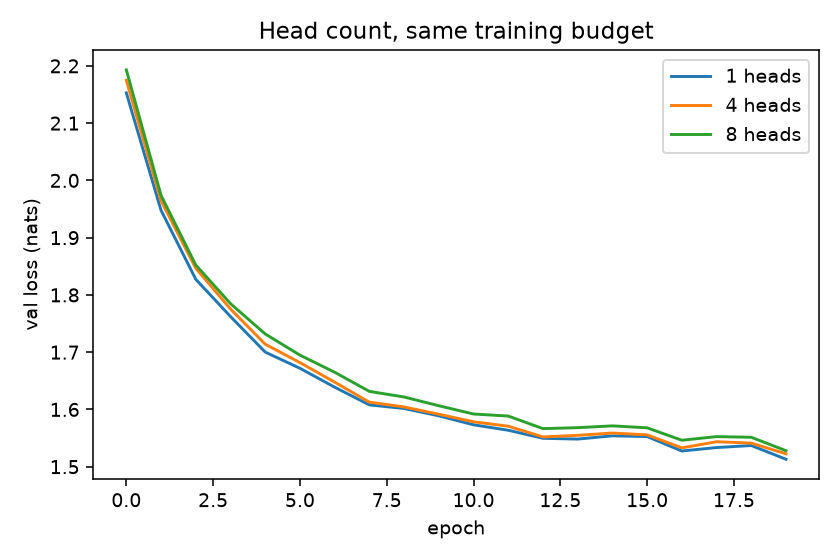

no_mask_loss.png


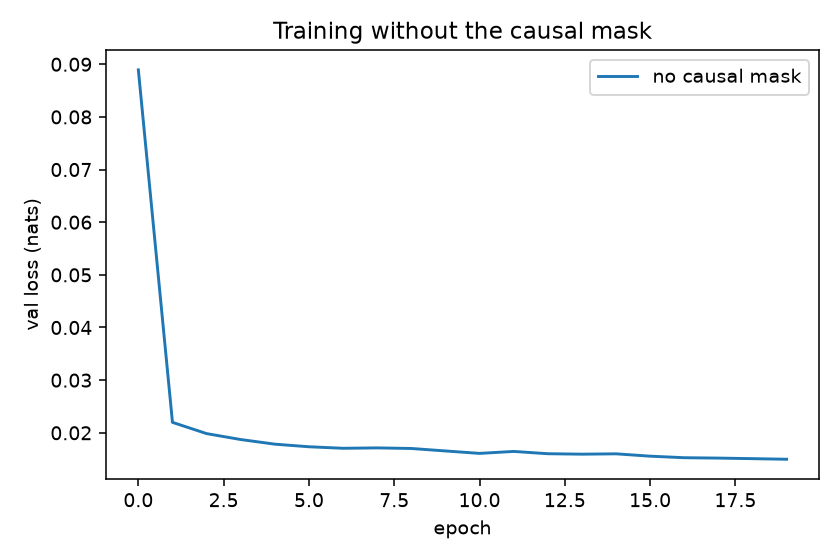

context_time.png


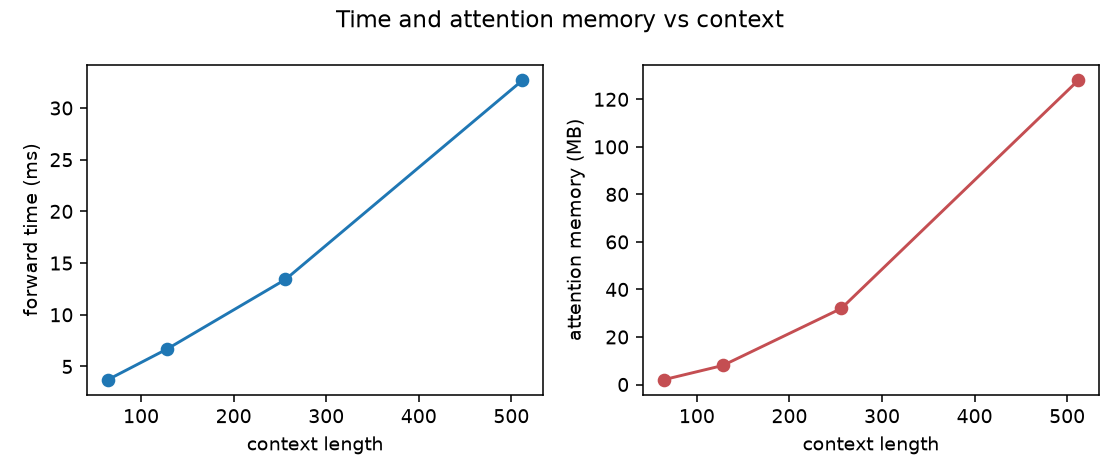

In [3]:
import pandas as pd
from IPython.display import Image, display

df = pd.read_csv(ROOT / 'results.csv')
print(df[df.problem == 'P2'][['model', 'val_loss_nats', 'bits_per_char', 'notes']])
print((ROOT / 'problem2' / 'generated_samples.txt').read_text()[:500])
for name in ['lm_val_loss.png', 'attention_heatmaps.png', 'heads_ablation.png', 'no_mask_loss.png', 'context_time.png']:
    print(name)
    display(Image(filename=str(ROOT / 'problem2' / 'figures' / name)))